# Critical-batch-size experiment (`cbs`)

This notebook runs the second experiment: fix the data budget at
\[
D = 2^{14},
\]
and sweep the batch size over integer and half-integer powers of two,
\[
B \in \{2^1,2^{1.5},2^2,2^{2.5},\dots,2^{12}\}.
\]
Because the batch size must be an integer, each value \(2^x\) is rounded to the nearest positive integer.

For each batch size:

- **SGD** searches the learning rate around its theory-scaled value;
- **Polyak** and **Nesterov** search both the learning rate and the momentum gap \(1-\rho\) around their theory-scaled values;
- any candidate with learning rate \(\eta>1\) is skipped without simulation.

For every admissible candidate, the code simulates the PLKR model and reports the mean tail loss (average over the final `TAIL_FRACTION` of training). The best candidate at each batch size is used to produce the final batch-size-vs-loss plot.

All outputs are saved into the folder
```text
cbs/
```
under the notebook's current working directory, with the main figure saved as
```text
cbs/cbs.pdf
cbs/cbs.png
```


In [42]:

import time
import zlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# =============================================================================
# 1. Global configuration
# =============================================================================

BETA = 4.0
S_VALUE = 0.3
SIGMA = 0.1
DIM = 4096
N_RUNS = 50
BASE_SEED = 20260802
TAIL_FRACTION = 0.01

D_FIXED = 2**14
# Explicit half-integer exponent grid:
# 1, 1.5, 2, 2.5, ..., 11.5, 12.
# Build it from integer numerators to avoid any floating-grid ambiguity.
# Use the explicit exponent grid 1, 1.5, 2, 2.5, ..., 12.
# We keep the exponent and rounded integer batch size paired in B_GRID.
B_GRID = [
    {
        "batch_exponent": half_step / 2.0,
        "B": max(1, int(np.floor(2.0 ** (half_step / 2.0) + 0.5))),
    }
    for half_step in range(1, 20)
]
B_EXPONENT_LIST = [item["batch_exponent"] for item in B_GRID]
B_LIST = [item["B"] for item in B_GRID]

ETA_MULTIPLIERS = [0.3, 1.0, 3.0]
MAX_LEARNING_RATE = 1.0
DIVERGENCE_LOSS = 1e12
GAP_MULTIPLIERS = [0.3, 1.0, 3.0]

ETA_CONSTANTS = {
    "sgd": 0.30,
    "hb": 0.10,
    "nag": 0.10,
}

# These are the prefactors in (1-rho) = gap_constant * D^{-b}.
GAP_CONSTANTS = {
    "hb": 1.0,
    "nag": 2.0,
}

TRANSIENT_SLACK = 0.01

GROUP_ORDER = ["sgd", "hb", "nag"]
GROUP_LABELS = {
    "sgd": "SGD",
    "hb": "Polyak",
    "nag": "Nesterov",
}
MARKERS = {
    "sgd": "o",
    "hb": "^",
    "nag": "s",
}

plt.rcParams.update({
    "text.usetex": False,
    "font.family": "sans-serif",
    "axes.titlesize": 16,
    "axes.labelsize": 16,
    "lines.linewidth": 2,
    "lines.markersize": 6,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.figsize": (5, 4),
    "legend.fontsize": 10,
    "legend.handlelength": 1,
})

# Create a cbs subfolder under the notebook current working directory.
OUTPUT_DIR = Path.cwd() / "cbs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BASE_OPTIMAL_EXPONENT = S_VALUE / (S_VALUE + 1.0)
POLYAK_MAX_BATCH_EXPONENT = (2.0 * S_VALUE + 1.0) / (2.0 * S_VALUE + 2.0)
NAG_MAX_BATCH_EXPONENT = (2.0 * S_VALUE * BETA + 1.0) / (2.0 * S_VALUE * BETA + BETA + 1.0)

B_SGD_CRITICAL = D_FIXED ** BASE_OPTIMAL_EXPONENT
B_POLYAK_CRITICAL = D_FIXED ** POLYAK_MAX_BATCH_EXPONENT
B_NAG_CROSSOVER = D_FIXED ** NAG_MAX_BATCH_EXPONENT

print(f"D_FIXED = {D_FIXED}")
print("Batch grid:")
for exponent, batch_size in zip(B_EXPONENT_LIST, B_LIST):
    print(f"  x={exponent:4.1f} -> B=round(2^x)={batch_size}")
print(f"SGD critical batch size ~ {B_SGD_CRITICAL:.3f}")
print(f"Nesterov crossover     ~ {B_NAG_CROSSOVER:.3f}")
print(f"Polyak critical batch size ~ {B_POLYAK_CRITICAL:.3f}")
print(f"Outputs will be saved in: {OUTPUT_DIR.resolve()}")


D_FIXED = 16384
Batch grid:
  x= 0.5 -> B=round(2^x)=1
  x= 1.0 -> B=round(2^x)=2
  x= 1.5 -> B=round(2^x)=3
  x= 2.0 -> B=round(2^x)=4
  x= 2.5 -> B=round(2^x)=6
  x= 3.0 -> B=round(2^x)=8
  x= 3.5 -> B=round(2^x)=11
  x= 4.0 -> B=round(2^x)=16
  x= 4.5 -> B=round(2^x)=23
  x= 5.0 -> B=round(2^x)=32
  x= 5.5 -> B=round(2^x)=45
  x= 6.0 -> B=round(2^x)=64
  x= 6.5 -> B=round(2^x)=91
  x= 7.0 -> B=round(2^x)=128
  x= 7.5 -> B=round(2^x)=181
  x= 8.0 -> B=round(2^x)=256
  x= 8.5 -> B=round(2^x)=362
  x= 9.0 -> B=round(2^x)=512
  x= 9.5 -> B=round(2^x)=724
SGD critical batch size ~ 9.388
Nesterov crossover     ~ 86.368
Polyak critical batch size ~ 392.183
Outputs will be saved in: /home/jnwang/momentum/data_scaling/cbs


In [35]:

# =============================================================================
# 2. Power-law kernel-regression problem
# =============================================================================

def build_problem(dim=DIM, beta=BETA, s=S_VALUE, dtype=np.float32):
    if dim < 1:
        raise ValueError("DIM must be positive.")
    if beta <= 1:
        raise ValueError("BETA must be greater than 1.")
    if s <= 0:
        raise ValueError("S_VALUE must be positive.")

    j = np.arange(1, dim + 1, dtype=np.float64)
    lam = j ** (-beta)
    theta_squared = j ** (-(1.0 + beta * (s - 1.0)))
    theta_star = np.sqrt(theta_squared)
    return lam.astype(dtype), theta_star.astype(dtype)


def excess_loss_batch(delta, lam):
    return 0.5 * np.sum(lam[None, :] * delta * delta, axis=1, dtype=np.float64)


def excess_loss_single(delta, lam):
    return float(0.5 * np.sum(lam * delta * delta, dtype=np.float64))


LAM, THETA_STAR = build_problem()
print(f"lambda_1={LAM[0]:.6e}")
print(f"lambda_DIM={LAM[-1]:.6e}")
print(f"initial excess loss={excess_loss_single(-THETA_STAR, LAM):.6e}")


lambda_1=1.000000e+00
lambda_DIM=3.552714e-15
initial excess loss=7.452524e-01


In [36]:

# =============================================================================
# 3. Vectorized SGD / Heavy-Ball / Nesterov simulator
# =============================================================================

def stable_seed(*items):
    text = "|".join(str(item) for item in items)
    return (BASE_SEED + zlib.crc32(text.encode("utf-8"))) % (2**32 - 1)


def tail_length(num_steps):
    return max(1, int(np.ceil(num_steps * TAIL_FRACTION)))


def run_optimizer(algo, batch_size, num_steps, eta, rho=0.0, runs=N_RUNS, sigma=SIGMA, lam=LAM, theta_star=THETA_STAR, seed=None):
    if seed is None:
        seed = stable_seed(algo, batch_size, num_steps, eta, rho)

    rng = np.random.default_rng(seed)
    runs = int(runs)
    dim = lam.shape[0]

    delta = np.tile(-theta_star, (runs, 1)).astype(np.float32, copy=True)
    delta_previous = delta.copy()

    lam_row = lam[None, :]
    sqrt_lam_row = np.sqrt(lam)[None, :]

    tail_steps = tail_length(num_steps)
    tail_losses = np.empty((tail_steps, runs), dtype=np.float64)

    for step in range(1, num_steps + 1):
        if algo == "nag":
            evaluation_delta = delta + rho * (delta - delta_previous)
        else:
            evaluation_delta = delta

        with np.errstate(over="ignore", invalid="ignore"):
            evaluation_loss = excess_loss_batch(evaluation_delta, lam)

        if (
            not np.all(np.isfinite(evaluation_loss))
            or float(np.max(evaluation_loss)) >= DIVERGENCE_LOSS
        ):
            return np.full(runs, np.inf, dtype=np.float64)

        gaussian = rng.standard_normal(size=(runs, dim)).astype(np.float32, copy=False)
        noise_scale = np.sqrt((evaluation_loss + sigma**2) / batch_size).astype(np.float32)
        noise = noise_scale[:, None] * sqrt_lam_row * gaussian
        gradient = lam_row * evaluation_delta + noise

        if algo == "sgd":
            new_delta = delta - eta * gradient
        elif algo == "hb":
            new_delta = delta - eta * gradient + rho * (delta - delta_previous)
        elif algo == "nag":
            new_delta = evaluation_delta - eta * gradient
        else:
            raise ValueError(f"Unknown optimizer: {algo}")

        new_delta = new_delta.astype(np.float32, copy=False)
        if not np.all(np.isfinite(new_delta)):
            return np.full(runs, np.inf, dtype=np.float64)

        delta_previous, delta = delta, new_delta

        if step > num_steps - tail_steps:
            with np.errstate(over="ignore", invalid="ignore"):
                current_loss = excess_loss_batch(delta, lam)
            if (
                not np.all(np.isfinite(current_loss))
                or float(np.max(current_loss)) >= DIVERGENCE_LOSS
            ):
                return np.full(runs, np.inf, dtype=np.float64)
            tail_losses[step - (num_steps - tail_steps) - 1] = current_loss

    return tail_losses.mean(axis=0)


In [37]:

# =============================================================================
# 4. Theory-scaled schedules as functions of batch size
# =============================================================================

def batch_exponent_from_B(B, D=D_FIXED):
    return float(np.log(B) / np.log(D))


def theory_params_for_batch(algo, B, D=D_FIXED):
    a = batch_exponent_from_B(B, D)

    if algo == "sgd":
        c = max(BASE_OPTIMAL_EXPONENT - a, 0.0)
        eta = ETA_CONSTANTS["sgd"] * D ** (-c)
        return {
            "a": a,
            "b": 0.0,
            "c": c,
            "eta": float(eta),
            "one_minus_rho": 1.0,
            "rho": 0.0,
        }

    if algo == "hb":
        if a <= BASE_OPTIMAL_EXPONENT:
            b = 0.0
            c = BASE_OPTIMAL_EXPONENT - a
        elif a <= POLYAK_MAX_BATCH_EXPONENT:
            b = a - BASE_OPTIMAL_EXPONENT
            c = 0.0
        else:
            b = max(1.0 - a - TRANSIENT_SLACK, 0.0)
            c = 0.0
        eta = ETA_CONSTANTS["hb"] * D ** (-c)
        one_minus_rho = min(1.0, GAP_CONSTANTS["hb"] * D ** (-b))
        return {
            "a": a,
            "b": b,
            "c": c,
            "eta": float(eta),
            "one_minus_rho": float(one_minus_rho),
            "rho": float(1.0 - one_minus_rho),
        }

    if algo == "nag":
        if a <= BASE_OPTIMAL_EXPONENT:
            b = 0.0
            c = BASE_OPTIMAL_EXPONENT - a
        elif a <= NAG_MAX_BATCH_EXPONENT:
            b = BETA * ((S_VALUE + 1.0) * a - S_VALUE) / (S_VALUE * BETA + 1.0)
            c = 0.0
        else:
            b = max(1.0 - a - TRANSIENT_SLACK, 0.0)
            c = 0.0
        eta = ETA_CONSTANTS["nag"] * D ** (-c)
        one_minus_rho = min(1.0, GAP_CONSTANTS["nag"] * D ** (-b))
        return {
            "a": a,
            "b": b,
            "c": c,
            "eta": float(eta),
            "one_minus_rho": float(one_minus_rho),
            "rho": float(1.0 - one_minus_rho),
        }

    raise ValueError(f"Unknown optimizer: {algo}")


preview_rows = []
for group in GROUP_ORDER:
    for batch_exponent, B in zip(B_EXPONENT_LIST, B_LIST):
        row = theory_params_for_batch(group, B)
        row.update({"group": group, "batch_exponent": batch_exponent, "B": B, "K": D_FIXED // B})
        preview_rows.append(row)

theory_preview = pd.DataFrame(preview_rows)
display(theory_preview)


,a,b,c,eta,one_minus_rho,rho,group,batch_exponent,B,K
0,0.000000,0.000000,0.230769,0.031957,1.000000,0.000000,sgd,0.5,1,16384
1,0.071429,0.000000,0.159341,0.063914,1.000000,0.000000,sgd,1.0,2,8192
2,0.113212,0.000000,0.117558,0.095870,1.000000,0.000000,sgd,1.5,3,5461
3,0.142857,0.000000,0.087912,0.127827,1.000000,0.000000,sgd,2.0,4,4096
4,0.184640,0.000000,0.046129,0.191741,1.000000,0.000000,sgd,2.5,6,2730
5,0.214286,0.000000,0.016484,0.255654,1.000000,0.000000,sgd,3.0,8,2048
6,0.247102,0.000000,0.000000,0.300000,1.000000,0.000000,sgd,3.5,11,1489
7,0.285714,0.000000,0.000000,0.300000,1.000000,0.000000,sgd,4.0,16,1024
8,0.323112,0.000000,0.000000,0.300000,1.000000,0.000000,sgd,4.5,23,712
9,0.357143,0.000000,0.000000,0.300000,1.000000,0.000000,sgd,5.0,32,512


In [38]:

# =============================================================================
# 5. Search around theory-scaled schedules
# =============================================================================

def search_one_batch(algo, B, D=D_FIXED):
    K = max(1, D // B)
    theory = theory_params_for_batch(algo, B, D)

    search_rows = []

    if algo == "sgd":
        for eta_mult in ETA_MULTIPLIERS:
            eta = theory["eta"] * eta_mult
            if eta > MAX_LEARNING_RATE:
                continue
            seed = stable_seed("cbs", algo, B, eta_mult)
            tail_mean_losses = run_optimizer(
                algo=algo,
                batch_size=B,
                num_steps=K,
                eta=eta,
                rho=0.0,
                seed=seed,
            )
            search_rows.append({
                "group": algo,
                "B": B,
                "K": K,
                "eta_mult": eta_mult,
                "gap_mult": np.nan,
                "eta": float(eta),
                "one_minus_rho": 1.0,
                "rho": 0.0,
                "mean_loss": float(tail_mean_losses.mean()),
                "std_loss": float(tail_mean_losses.std(ddof=0)),
            })
    else:
        for eta_mult in ETA_MULTIPLIERS:
            eta = theory["eta"] * eta_mult
            if eta > MAX_LEARNING_RATE:
                continue
            for gap_mult in GAP_MULTIPLIERS:
                one_minus_rho = min(1.0, theory["one_minus_rho"] * gap_mult)
                rho = 1.0 - one_minus_rho
                seed = stable_seed("cbs", algo, B, eta_mult, gap_mult)
                tail_mean_losses = run_optimizer(
                    algo=algo,
                    batch_size=B,
                    num_steps=K,
                    eta=eta,
                    rho=rho,
                    seed=seed,
                )
                search_rows.append({
                    "group": algo,
                    "B": B,
                    "K": K,
                    "eta_mult": eta_mult,
                    "gap_mult": gap_mult,
                    "eta": float(eta),
                    "one_minus_rho": float(one_minus_rho),
                    "rho": float(rho),
                    "mean_loss": float(tail_mean_losses.mean()),
                    "std_loss": float(tail_mean_losses.std(ddof=0)),
                })

    search_df = pd.DataFrame(search_rows)
    if search_df.empty:
        raise RuntimeError(
            f"No learning-rate candidate satisfies eta <= {MAX_LEARNING_RATE} "
            f"for {algo} at B={B}."
        )

    search_df["is_finite"] = np.isfinite(search_df["mean_loss"])
    finite_df = search_df[search_df["is_finite"]]
    if finite_df.empty:
        raise RuntimeError(f"All admissible candidates diverged for {algo} at B={B}.")

    best_index = finite_df["mean_loss"].idxmin()
    best_row = search_df.loc[best_index].copy()

    theory_prefixed = {f"theory_{k}": v for k, v in theory.items()}
    for k, v in theory_prefixed.items():
        best_row[k] = v

    return search_df, best_row


In [39]:

# =============================================================================
# 6. Run the full critical-batch-size experiment
# =============================================================================

ALL_SEARCH_RESULTS = []
BEST_ROWS = []

for group in GROUP_ORDER:
    print("=" * 80)
    print(f"Searching over batch sizes for {GROUP_LABELS[group]}")
    print("=" * 80)
    for batch_exponent, B in zip(B_EXPONENT_LIST, B_LIST):
        start_time = time.time()
        search_df, best_row = search_one_batch(group, B)
        runtime = time.time() - start_time

        search_df["batch_exponent"] = batch_exponent
        best_row["batch_exponent"] = batch_exponent
        search_df["runtime_seconds"] = runtime
        best_row["runtime_seconds"] = runtime

        ALL_SEARCH_RESULTS.append(search_df)
        BEST_ROWS.append(best_row)

        print(
            f"x={batch_exponent:4.1f} | B={B:5d} | K={int(best_row['K']):5d} | "
            f"best loss={best_row['mean_loss']:.6e} | "
            f"eta_mult={best_row['eta_mult']:.1f}"
            + (
                ""
                if group == "sgd"
                else f" | gap_mult={best_row['gap_mult']:.1f}"
            )
            + f" | elapsed={runtime:.1f}s"
        )

SEARCH_RESULTS_DF = pd.concat(ALL_SEARCH_RESULTS, ignore_index=True)
BEST_RESULTS_DF = pd.DataFrame(BEST_ROWS).sort_values(["group", "B"]).reset_index(drop=True)

display(BEST_RESULTS_DF)

SEARCH_RESULTS_DF.to_csv(OUTPUT_DIR / "cbs_search_results.csv", index=False)
BEST_RESULTS_DF.to_csv(OUTPUT_DIR / "cbs_best_results.csv", index=False)
print(f"Saved search tables to: {OUTPUT_DIR.resolve()}")


Searching over batch sizes for SGD
x= 0.5 | B=    1 | K=16384 | best loss=3.460033e-02 | eta_mult=3.0 | elapsed=200.3s
x= 1.0 | B=    2 | K= 8192 | best loss=3.470914e-02 | eta_mult=3.0 | elapsed=100.4s
x= 1.5 | B=    3 | K= 5461 | best loss=3.477002e-02 | eta_mult=3.0 | elapsed=66.8s
x= 2.0 | B=    4 | K= 4096 | best loss=3.487365e-02 | eta_mult=3.0 | elapsed=50.1s
x= 2.5 | B=    6 | K= 2730 | best loss=3.493889e-02 | eta_mult=3.0 | elapsed=33.4s
x= 3.0 | B=    8 | K= 2048 | best loss=3.516853e-02 | eta_mult=3.0 | elapsed=25.0s
x= 3.5 | B=   11 | K= 1489 | best loss=3.673132e-02 | eta_mult=3.0 | elapsed=18.2s
x= 4.0 | B=   16 | K= 1024 | best loss=4.059100e-02 | eta_mult=3.0 | elapsed=12.5s
x= 4.5 | B=   23 | K=  712 | best loss=4.471310e-02 | eta_mult=3.0 | elapsed=8.7s
x= 5.0 | B=   32 | K=  512 | best loss=4.913986e-02 | eta_mult=3.0 | elapsed=6.3s
x= 5.5 | B=   45 | K=  364 | best loss=5.407822e-02 | eta_mult=3.0 | elapsed=4.5s
x= 6.0 | B=   64 | K=  256 | best loss=5.985259e-02 |

,group,B,K,eta_mult,gap_mult,eta,one_minus_rho,rho,mean_loss,std_loss,is_finite,theory_a,theory_b,theory_c,theory_eta,theory_one_minus_rho,theory_rho,batch_exponent,runtime_seconds
0,hb,1,16384,3.0,0.3,0.031957,0.300000,0.700000,0.033706,0.000439,True,0.000000,0.000000,0.230769,0.010652,1.000000,0.000000,0.5,629.943450
1,hb,2,8192,3.0,0.3,0.063914,0.300000,0.700000,0.033580,0.000442,True,0.071429,0.000000,0.159341,0.021305,1.000000,0.000000,1.0,316.260141
2,hb,3,5461,3.0,0.3,0.095870,0.300000,0.700000,0.033553,0.000496,True,0.113212,0.000000,0.117558,0.031957,1.000000,0.000000,1.5,210.599100
3,hb,4,4096,3.0,0.3,0.127827,0.300000,0.700000,0.033636,0.000522,True,0.142857,0.000000,0.087912,0.042609,1.000000,0.000000,2.0,157.652050
4,hb,6,2730,3.0,0.3,0.191741,0.300000,0.700000,0.033548,0.000616,True,0.184640,0.000000,0.046129,0.063914,1.000000,0.000000,2.5,105.145533
5,hb,8,2048,3.0,0.3,0.255654,0.300000,0.700000,0.033698,0.000704,True,0.214286,0.000000,0.016484,0.085218,1.000000,0.000000,3.0,78.889218
6,hb,11,1489,3.0,0.3,0.300000,0.256028,0.743972,0.033690,0.000711,True,0.247102,0.016333,0.000000,0.100000,0.853426,0.146574,3.5,57.343519
7,hb,16,1024,3.0,0.3,0.300000,0.176019,0.823981,0.033906,0.001058,True,0.285714,0.054945,0.000000,0.100000,0.586730,0.413270,4.0,39.998217
8,hb,23,712,3.0,0.3,0.300000,0.122448,0.877552,0.033535,0.001096,True,0.323112,0.092342,0.000000,0.100000,0.408160,0.591840,4.5,27.861474
9,hb,32,512,3.0,0.3,0.300000,0.088010,0.911990,0.033533,0.000907,True,0.357143,0.126374,0.000000,0.100000,0.293365,0.706635,5.0,20.038369


Saved search tables to: /home/jnwang/momentum/data_scaling/cbs


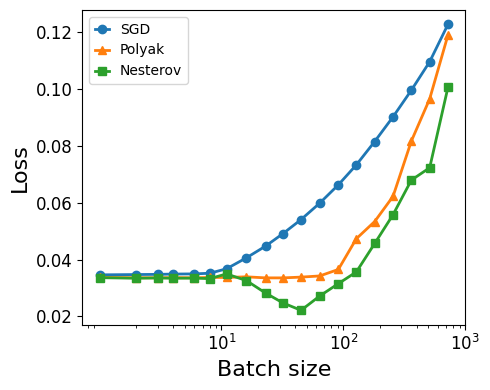

Saved figure to: /home/jnwang/momentum/data_scaling/cbs/cbs.pdf


In [44]:

# =============================================================================
# 7. Plot batch size versus best loss
# =============================================================================

def plot_cbs(best_results_df):
    plt.figure()

    b_values = best_results_df["B"].to_numpy(dtype=np.float64)
    x_min = float(np.min(b_values))
    x_max = 2.0 ** 8.5

    # Three batch-size regimes.  Use light background colors:
    # The large/ultra-large boundary is fixed at B=128.
    ultra_large_boundary = 128.0

    #   small-batch       -> light blue
    #   large-batch       -> light red
    #   ultra large-batch -> light green
    plt.axvspan(
        x_min,
        B_SGD_CRITICAL,
        color="lightskyblue",
        alpha=0.25,
        zorder=0,
    )
    plt.axvspan(
        B_SGD_CRITICAL,
        ultra_large_boundary,
        color="lightcoral",
        alpha=0.20,
        zorder=0,
    )
    plt.axvspan(
        ultra_large_boundary,
        x_max,
        color="lightgreen",
        alpha=0.25,
        zorder=0,
    )

    for group in GROUP_ORDER:
        group_df = best_results_df[best_results_df["group"] == group].sort_values("B")
        plt.plot(
            group_df["B"].to_numpy(dtype=np.float64),
            group_df["mean_loss"].to_numpy(dtype=np.float64),
            marker=MARKERS[group],
            label=GROUP_LABELS[group],
            zorder=3,
        )

    plt.axvline(
        B_SGD_CRITICAL,
        linestyle="--",
        color="black",
        linewidth=1.0,
        alpha=0.6,
        zorder=1,
    )
    plt.axvline(
        ultra_large_boundary,
        linestyle="--",
        color="black",
        linewidth=1.0,
        alpha=0.6,
        zorder=1,
    )

    plt.xscale("log", base=10)
    plt.xlim(x_min, x_max)
    plt.xlabel("Batch size")
    plt.ylabel("Loss")
    plt.xticks(
        [1e1, 1e2, 1e3],
        [r"$10^1$", r"$10^2$", r"$10^3$"],
    )
    plt.legend(loc="best")
    plt.tight_layout()

    pdf_path = OUTPUT_DIR / "cbs.pdf"
    png_path = OUTPUT_DIR / "cbs.png"
    plt.savefig(pdf_path, bbox_inches="tight")
    plt.savefig(png_path, bbox_inches="tight")
    plt.show()

    return pdf_path, png_path


PDF_PATH, PNG_PATH = plot_cbs(BEST_RESULTS_DF)
print(f"Saved figure to: {PDF_PATH}")


In [41]:

# =============================================================================
# 8. Compact summary
# =============================================================================

SUMMARY_COLUMNS = [
    "group",
    "batch_exponent",
    "B",
    "K",
    "mean_loss",
    "eta",
    "rho",
    "one_minus_rho",
    "eta_mult",
    "gap_mult",
    "theory_eta",
    "theory_rho",
    "theory_one_minus_rho",
]

SUMMARY_TABLE = BEST_RESULTS_DF[SUMMARY_COLUMNS].copy()
display(SUMMARY_TABLE)

print("Main outputs:")
print(f"  Figure (PDF): {PDF_PATH}")
print(f"  Figure (PNG): {PNG_PATH}")
print(f"  Search CSV:   {OUTPUT_DIR / 'cbs_search_results.csv'}")
print(f"  Best CSV:     {OUTPUT_DIR / 'cbs_best_results.csv'}")


,group,batch_exponent,B,K,mean_loss,eta,rho,one_minus_rho,eta_mult,gap_mult,theory_eta,theory_rho,theory_one_minus_rho
0,hb,0.5,1,16384,0.033706,0.031957,0.700000,0.300000,3.0,0.3,0.010652,0.000000,1.000000
1,hb,1.0,2,8192,0.033580,0.063914,0.700000,0.300000,3.0,0.3,0.021305,0.000000,1.000000
2,hb,1.5,3,5461,0.033553,0.095870,0.700000,0.300000,3.0,0.3,0.031957,0.000000,1.000000
3,hb,2.0,4,4096,0.033636,0.127827,0.700000,0.300000,3.0,0.3,0.042609,0.000000,1.000000
4,hb,2.5,6,2730,0.033548,0.191741,0.700000,0.300000,3.0,0.3,0.063914,0.000000,1.000000
5,hb,3.0,8,2048,0.033698,0.255654,0.700000,0.300000,3.0,0.3,0.085218,0.000000,1.000000
6,hb,3.5,11,1489,0.033690,0.300000,0.743972,0.256028,3.0,0.3,0.100000,0.146574,0.853426
7,hb,4.0,16,1024,0.033906,0.300000,0.823981,0.176019,3.0,0.3,0.100000,0.413270,0.586730
8,hb,4.5,23,712,0.033535,0.300000,0.877552,0.122448,3.0,0.3,0.100000,0.591840,0.408160
9,hb,5.0,32,512,0.033533,0.300000,0.911990,0.088010,3.0,0.3,0.100000,0.706635,0.293365


Main outputs:
  Figure (PDF): /home/jnwang/momentum/data_scaling/cbs/cbs.pdf
  Figure (PNG): /home/jnwang/momentum/data_scaling/cbs/cbs.png
  Search CSV:   /home/jnwang/momentum/data_scaling/cbs/cbs_search_results.csv
  Best CSV:     /home/jnwang/momentum/data_scaling/cbs/cbs_best_results.csv
